GAUSSIAN ENTROPY VERIFICATION

 sigma  Numerical_Mass  Second_Moment  Expected_Second_Moment  Numerical_Entropy  Exact_Entropy  Entropy_Error  Numerical_Reduced_Entropy  Expected_-log_sigma  Reduced_Error
  0.50             1.0         0.2500                  0.2500          -0.725791      -0.725791  -1.110223e-16               6.931472e-01             0.693147  -1.110223e-16
  0.75             1.0         0.5625                  0.5625          -1.131256      -1.131256  -2.220446e-16               2.876821e-01             0.287682  -1.110223e-16
  1.00             1.0         1.0000                  1.0000          -1.418939      -1.418939   2.220446e-16               2.220446e-16            -0.000000   2.220446e-16
  1.50             1.0         2.2500                  2.2500          -1.824404      -1.824404  -2.220446e-16              -4.054651e-01            -0.405465  -2.220446e-16
  2.00             1.0         4.0000                  4.0000          -2.112086      -2.112086   0

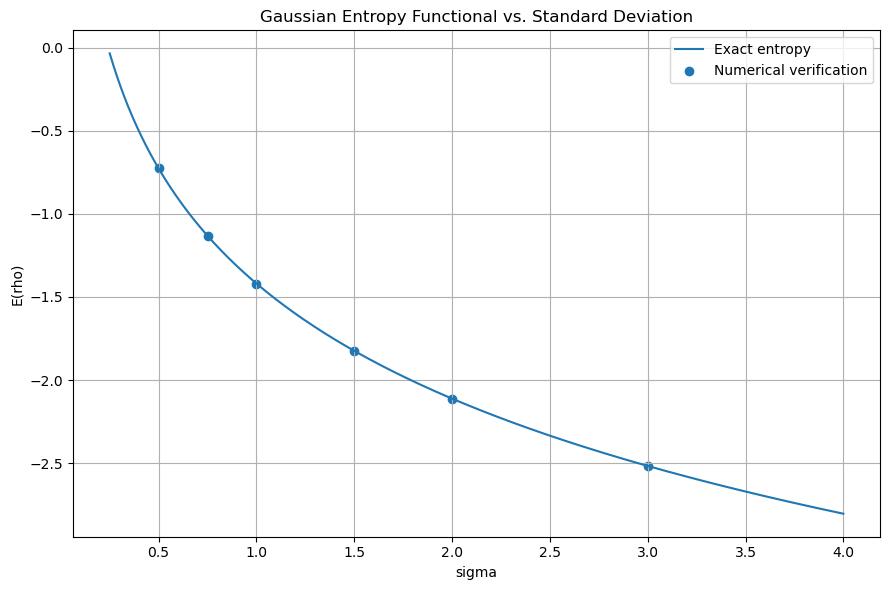

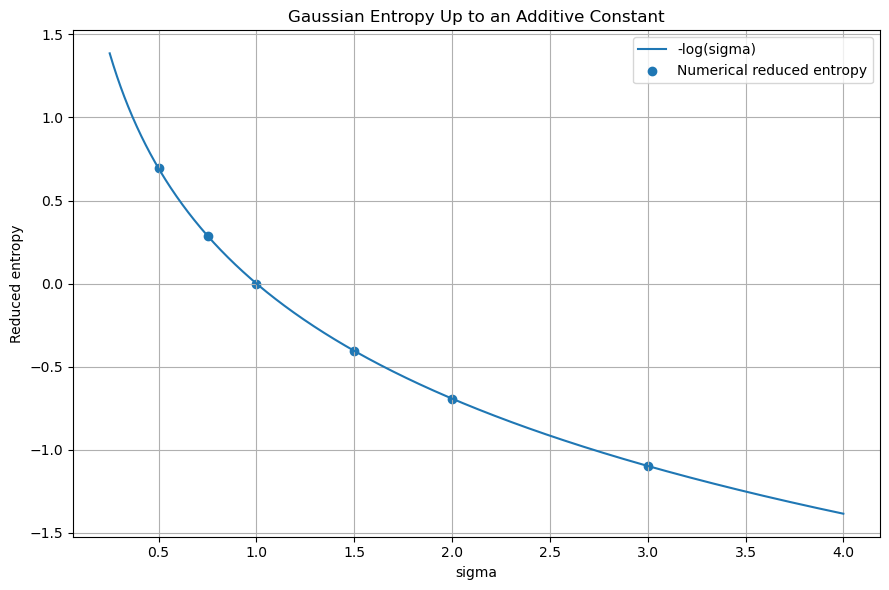


FINAL RESULT

E(rho) = -1/2 log(2 pi e sigma^2)

Up to constants independent of sigma:
E(rho) = -log(sigma)


In [1]:
# ============================================================
# HOMEWORK 4.2 - PART I
# ENTROPY OF A GAUSSIAN
# STANDALONE VERIFICATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# GAUSSIAN DENSITY
# ============================================================

def gaussian_density(
    x,
    sigma
):

    return (

        1.0

        /

        (
            np.sqrt(2.0 * np.pi)
            *
            sigma
        )

        *

        np.exp(

            -x**2

            /

            (
                2.0
                *
                sigma**2
            )
        )
    )


# ============================================================
# EXACT ENTROPY FUNCTIONAL
#
# E(rho)
# =
# integral rho log(rho) dx
#
# =
# -1/2 log(2 pi e sigma^2)
# ============================================================

def exact_entropy(
    sigma
):

    return (

        -0.5

        *

        np.log(

            2.0
            *
            np.pi
            *
            np.e
            *
            sigma**2
        )
    )


# ============================================================
# REDUCED ENTROPY
#
# Remove the sigma-independent constant:
#
# E(rho) + 1/2 log(2 pi e)
#
# should equal
#
# -log(sigma)
# ============================================================

def reduced_entropy(
    sigma
):

    return (
        -np.log(
            sigma
        )
    )


# ============================================================
# TEST VALUES
# ============================================================

sigma_values = np.array([
    0.5,
    0.75,
    1.0,
    1.5,
    2.0,
    3.0
])


results = []


for sigma in sigma_values:

    # Use a large interval relative to sigma
    x = np.linspace(
        -10.0 * sigma,
        10.0 * sigma,
        50001
    )


    rho = gaussian_density(
        x,
        sigma
    )


    # ========================================================
    # NORMALIZATION
    # ========================================================

    mass = np.trapz(
        rho,
        x
    )


    # ========================================================
    # SECOND MOMENT
    # ========================================================

    second_moment = np.trapz(
        x**2 * rho,
        x
    )


    # ========================================================
    # NUMERICAL ENTROPY
    #
    # rho > 0 everywhere on this finite grid
    # ========================================================

    numerical_entropy = np.trapz(

        rho
        *
        np.log(rho),

        x
    )


    theoretical_entropy = exact_entropy(
        sigma
    )


    entropy_error = (

        numerical_entropy

        -

        theoretical_entropy
    )


    # ========================================================
    # REDUCED ENTROPY CHECK
    # ========================================================

    numerical_reduced_entropy = (

        numerical_entropy

        +

        0.5
        *
        np.log(
            2.0
            *
            np.pi
            *
            np.e
        )
    )


    theoretical_reduced_entropy = reduced_entropy(
        sigma
    )


    reduced_error = (

        numerical_reduced_entropy

        -

        theoretical_reduced_entropy
    )


    results.append({

        "sigma":
            sigma,

        "Numerical_Mass":
            mass,

        "Second_Moment":
            second_moment,

        "Expected_Second_Moment":
            sigma**2,

        "Numerical_Entropy":
            numerical_entropy,

        "Exact_Entropy":
            theoretical_entropy,

        "Entropy_Error":
            entropy_error,

        "Numerical_Reduced_Entropy":
            numerical_reduced_entropy,

        "Expected_-log_sigma":
            theoretical_reduced_entropy,

        "Reduced_Error":
            reduced_error

    })


results_df = pd.DataFrame(
    results
)


# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 80)

print(
    "GAUSSIAN ENTROPY VERIFICATION"
)

print("=" * 80)

print()

print(
    results_df.to_string(
        index=False
    )
)


# ============================================================
# ERROR SUMMARIES
# ============================================================

max_mass_error = np.max(

    np.abs(

        results_df[
            "Numerical_Mass"
        ]

        -

        1.0
    )
)


max_second_moment_error = np.max(

    np.abs(

        results_df[
            "Second_Moment"
        ]

        -

        results_df[
            "Expected_Second_Moment"
        ]
    )
)


max_entropy_error = np.max(

    np.abs(

        results_df[
            "Entropy_Error"
        ]
    )
)


max_reduced_error = np.max(

    np.abs(

        results_df[
            "Reduced_Error"
        ]
    )
)


print()

print("=" * 80)

print(
    "AUTOMATIC VERIFICATION"
)

print("=" * 80)

print(
    "Maximum normalization error =",
    max_mass_error
)

print(
    "Maximum second-moment error =",
    max_second_moment_error
)

print(
    "Maximum entropy error =",
    max_entropy_error
)

print(
    "Maximum reduced-entropy error =",
    max_reduced_error
)


# ============================================================
# ASSERTIONS
# ============================================================

assert max_mass_error < 1e-10

assert max_second_moment_error < 1e-9

assert max_entropy_error < 1e-9

assert max_reduced_error < 1e-9


print()

print(
    "PASS: Gaussian densities integrate to 1."
)

print(
    "PASS: Numerical second moments agree with sigma^2."
)

print(
    "PASS: Numerical entropy agrees with"
)

print(
    "      -1/2 log(2 pi e sigma^2)."
)

print(
    "PASS: After removing the constant,"
)

print(
    "      E(rho) = -log(sigma)."
)


# ============================================================
# PLOT ENTROPY VS SIGMA
# ============================================================

sigma_plot = np.linspace(
    0.25,
    4.0,
    1000
)


entropy_plot = exact_entropy(
    sigma_plot
)


plt.figure(
    figsize=(9, 6)
)


plt.plot(
    sigma_plot,
    entropy_plot,
    label="Exact entropy"
)


plt.scatter(
    sigma_values,
    results_df[
        "Numerical_Entropy"
    ],
    label="Numerical verification"
)


plt.xlabel(
    "sigma"
)

plt.ylabel(
    "E(rho)"
)

plt.title(
    "Gaussian Entropy Functional vs. Standard Deviation"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part1_gaussian_entropy.png",
    dpi=300
)


plt.show()


# ============================================================
# PLOT REDUCED ENTROPY
# ============================================================

plt.figure(
    figsize=(9, 6)
)


plt.plot(
    sigma_plot,
    -np.log(
        sigma_plot
    ),
    label="-log(sigma)"
)


plt.scatter(
    sigma_values,
    results_df[
        "Numerical_Reduced_Entropy"
    ],
    label="Numerical reduced entropy"
)


plt.xlabel(
    "sigma"
)

plt.ylabel(
    "Reduced entropy"
)

plt.title(
    "Gaussian Entropy Up to an Additive Constant"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()


plt.savefig(
    "hw42_part1_reduced_entropy.png",
    dpi=300
)


plt.show()


# ============================================================
# FINAL RESULT
# ============================================================

print()

print("=" * 80)

print(
    "FINAL RESULT"
)

print("=" * 80)

print()

print(
    "E(rho) = -1/2 log(2 pi e sigma^2)"
)

print()

print(
    "Up to constants independent of sigma:"
)

print(
    "E(rho) = -log(sigma)"
)